# ENSP355 – Lab 4: Explainable and Privacy-Aware AI Threat Alert

**Student:** Aditya  
**Roll Number:** 2401010245  
**K.R. Mangalam University · 2026–27**

This notebook completes Q1–Q5 from the supplied Lab 4 manual. Upload `simple_cyber_activity.csv` to the Colab session before running all cells.

## Setup and load dataset

The earlier available synthetic dataset's `data_transfer_mb` field is named `download_mb` here to match the Lab 4 manual. The original Lab 2 model file was not part of the uploaded PDF, so the Decision Tree is retrained reproducibly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

try:
    data = pd.read_csv("simple_cyber_activity.csv")
except FileNotFoundError:
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_csv = next(name for name in uploaded if name.lower().endswith(".csv"))
        data = pd.read_csv(uploaded_csv)
    except ImportError:
        raise FileNotFoundError("Place simple_cyber_activity.csv beside this notebook and rerun.")
features = ["failed_logins", "login_hour", "new_device", "download_mb"]
X = data[features]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

print("Dataset shape:", data.shape)
print("Class counts (0=Normal, 1=Suspicious):")
display(y.value_counts().sort_index().rename(index={0:"Normal", 1:"Suspicious"}))
print(f"Decision Tree test accuracy: {accuracy_score(y_test, model.predict(X_test))*100:.2f}%")
print("Confusion matrix [Normal, Suspicious]:")
print(confusion_matrix(y_test, model.predict(X_test), labels=[0, 1]))

Dataset shape: (100, 5)
Class counts (0=Normal, 1=Suspicious):


label
Normal        70
Suspicious    30
Name: count, dtype: int64

Decision Tree test accuracy: 88.00%
Confusion matrix [Normal, Suspicious]:
[[16  2]
 [ 1  6]]


## Q1. Baseline predictions with confidence (5 marks)

In [2]:
samples = pd.DataFrame([
    {"account_id": "ACC-1001", "ip_address": "192.168.10.24", "failed_logins": 0, "login_hour": 10, "new_device": 0, "download_mb": 40},
    {"account_id": "ACC-1002", "ip_address": "10.0.4.18", "failed_logins": 7, "login_hour": 2, "new_device": 1, "download_mb": 150},
    {"account_id": "ACC-1003", "ip_address": "172.16.8.90", "failed_logins": 1, "login_hour": 15, "new_device": 0, "download_mb": 720},
    {"account_id": "ACC-1004", "ip_address": "192.168.20.11", "failed_logins": 4, "login_hour": 23, "new_device": 1, "download_mb": 400},
    {"account_id": "ACC-1005", "ip_address": "10.1.1.9", "failed_logins": 2, "login_hour": 9, "new_device": 0, "download_mb": 80},
])
predictions = model.predict(samples[features])
samples["prediction"] = ["Suspicious" if p == 1 else "Normal" for p in predictions]
samples["confidence"] = model.predict_proba(samples[features]).max(axis=1).round(3)
display(samples)

lowest_confidence = samples["confidence"].min()
print("Lowest confidence:", lowest_confidence)
print("Record(s) with lowest confidence:",
      ", ".join(samples.loc[samples["confidence"] == lowest_confidence, "account_id"]))
print("Confidence is not certainty: it is the model's estimated class probability, not proof that an event is safe or malicious.")

,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.0
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.0
2,ACC-1003,172.16.8.90,1,15,0,720,Suspicious,1.0
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.0
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,1.0


Lowest confidence: 1.0
Record(s) with lowest confidence: ACC-1001, ACC-1002, ACC-1003, ACC-1004, ACC-1005
Confidence is not certainty: it is the model's estimated class probability, not proof that an event is safe or malicious.


## Q2. Feature importance and explanation (10 marks)

,feature,importance
3,download_mb,0.822134
0,failed_logins,0.177866
1,login_hour,0.000000
2,new_device,0.000000


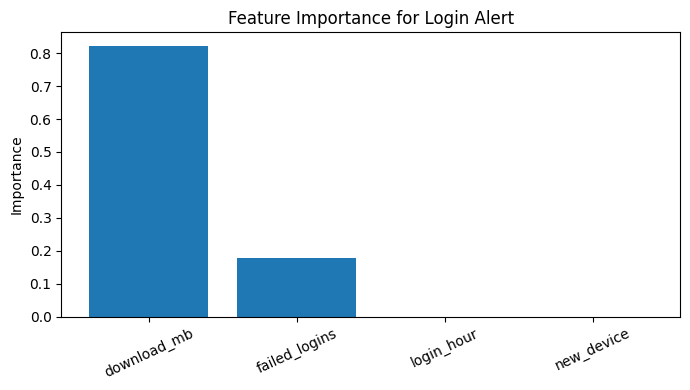

download_mb: Download volume was the most influential feature in this fitted tree.
failed_logins: Failed login attempts were the second most influential feature.
login_hour: Login hour had zero importance in this fitted tree; it was not used for its splits.


In [3]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)
display(importance)

plt.figure(figsize=(7, 4))
plt.bar(importance["feature"], importance["importance"])
plt.title("Feature Importance for Login Alert")
plt.ylabel("Importance")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

explanations = {
    "download_mb": "Download volume was the most influential feature in this fitted tree.",
    "failed_logins": "Failed login attempts were the second most influential feature.",
    "login_hour": "Login hour had zero importance in this fitted tree; it was not used for its splits.",
    "new_device": "New-device status had zero importance in this fitted tree; it was not used for its splits."
}
for feature in importance.head(3)["feature"]:
    print(f"{feature}: {explanations[feature]}")

**Caution:** Feature importance describes how the fitted model used its inputs; it does not prove that a feature causes suspicious activity.

## Q3. Controlled sensitivity test (10 marks)

In [4]:
baseline = samples.iloc[[4]].copy()
changed = baseline.copy()
changed["failed_logins"] = 8  # only this one feature is changed

baseline_prediction = model.predict(baseline[features])[0]
baseline_confidence = model.predict_proba(baseline[features]).max()
changed_prediction = model.predict(changed[features])[0]
changed_confidence = model.predict_proba(changed[features]).max()

sensitivity_results = pd.DataFrame([
    {"case": "Baseline", "failed_logins": int(baseline.iloc[0]["failed_logins"]),
     "prediction": "Suspicious" if baseline_prediction == 1 else "Normal",
     "confidence": round(float(baseline_confidence), 3)},
    {"case": "Changed", "failed_logins": int(changed.iloc[0]["failed_logins"]),
     "prediction": "Suspicious" if changed_prediction == 1 else "Normal",
     "confidence": round(float(changed_confidence), 3)}
])
display(sensitivity_results)
print("Only failed_logins changed from 2 to 8; all other inputs remained fixed.")

,case,failed_logins,prediction,confidence
0,Baseline,2,Normal,1.0
1,Changed,8,Suspicious,1.0


Only failed_logins changed from 2 to 8; all other inputs remained fixed.


**Interpretation:** The baseline record is classified as Normal. When `failed_logins` is increased from 2 to 8, with every other input held constant, the model changes its classification to Suspicious. This demonstrates sensitivity to failed login count in the fitted tree. Confidence remains 1.000 because each prediction falls into a pure training leaf; this should not be mistaken for certainty.

## Q4. Privacy masking and responsible-use rules (5 marks)

In [5]:
def mask_ip(ip):
    parts = str(ip).split(".")
    if len(parts) == 4:
        return f"{parts[0]}.{parts[1]}.xxx.xxx"
    return "<MASKED_IP>"

def mask_account(account_id):
    text = str(account_id)
    return text[:4] + "***" + text[-2:]

samples["masked_ip"] = samples["ip_address"].apply(mask_ip)
samples["masked_account"] = samples["account_id"].apply(mask_account)

masked_output = samples[["masked_account", "masked_ip", "prediction", "confidence"]]
display(masked_output)

privacy_rules = [
    "Mask identifiers before display or export.",
    "Use sanitized data in classroom notebooks.",
    "Restrict access to unmasked records.",
    "Require human review for high-risk action."
]
for rule in privacy_rules:
    print("-", rule)

,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.0
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.0
2,ACC-***03,172.16.xxx.xxx,Suspicious,1.0
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.0
4,ACC-***05,10.1.xxx.xxx,Normal,1.0


- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


## Q5. Responsible alert generation (10 marks)

In [6]:
def numeric_reason(row):
    reasons = []
    if row["failed_logins"] >= 5:
        reasons.append("many failed logins")
    if row["new_device"] == 1:
        reasons.append("new device")
    if row["login_hour"] < 6 or row["login_hour"] > 22:
        reasons.append("unusual login time")
    if row["download_mb"] >= 500:
        reasons.append("large data download")
    return ", ".join(reasons) if reasons else "no strong warning"

def make_alert(row):
    reason = numeric_reason(row)
    if row["prediction"] == "Suspicious":
        severity = "High"
        action = "Verify, contain if required, and report."
    elif row["confidence"] < 0.70:
        severity = "Medium"
        action = "Send for analyst review before action."
    else:
        severity = "Low"
        action = "Continue normal monitoring."
    human_review = "Yes" if severity in ["High", "Medium"] else "No"
    return pd.Series([severity, reason, action, human_review],
                     index=["severity", "reason", "recommended_action", "human_review"])

alerts = samples.apply(make_alert, axis=1)
final_alerts = pd.concat([samples, alerts], axis=1)
display(final_alerts[[
    "masked_account", "prediction", "confidence", "severity",
    "reason", "recommended_action", "human_review"
]])

,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.0,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report.",Yes
2,ACC-***03,Suspicious,1.0,High,large data download,"Verify, contain if required, and report.",Yes
3,ACC-***04,Suspicious,1.0,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No


## Conclusion and limitation

The Decision Tree produces five baseline predictions with confidence, exposes feature importance, and shows a changed decision when only failed-login count is increased. Account IDs and IP addresses are masked before reporting. Alerts include severity, observable reasons, recommended action, and human-review status. The model is trained on a small synthetic dataset, so it may not represent real network behaviour. A confidence score is not certainty, and the prototype must not automatically punish or block an account. Human verification is required for high-risk alerts.